# Customer Churn Prediction using Machine Learning

Ce projet a pour objectif d’analyser les données des clients d’une entreprise de télécommunications afin de prédire si un client va quitter le service (churn) ou rester.

Le projet consiste à préparer les données, analyser les variables importantes et entraîner plusieurs modèles de classification afin de comparer leurs performances. 


## Objectif du projet

L’objectif principal de ce projet est de construire un modèle capable de prédire le départ des clients (churn).

Pour atteindre cet objectif, nous allons :

- explorer le dataset
- nettoyer les données
- transformer les variables catégorielles
- préparer les données pour l’apprentissage automatique
- entraîner et comparer plusieurs modèles de classification

## Importation des bibliothèques

Dans cette étape, nous importons les bibliothèques nécessaires pour la manipulation des données et leur analyse.

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import RFE
import pickle


print("Tous les imports sont chargés ")
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))



Tous les imports sont chargés 
/kaggle/input/datasets/abdullah0a/telecom-customer-churn-insights-for-analysis/customer_churn_data.csv


## Chargement du dataset

Nous chargeons maintenant le dataset contenant les informations des clients.

In [44]:
df = pd.read_csv('/kaggle/input/datasets/abdullah0a/telecom-customer-churn-insights-for-analysis/customer_churn_data.csv')
df.head()


,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,1,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,2,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,3,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,4,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,5,42,Male,32,69.01,Month-to-Month,NaN,2208.32,No,Yes


## Dimensions du dataset

Nous vérifions le nombre de lignes et de colonnes dans le dataset.

In [45]:
df.shape

(1000, 10)



Le dataset contient 1000 observations et 10 variables.

## Structure des données

Nous examinons les types des variables afin de distinguer les variables numériques et catégorielles.

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       1000 non-null   int64  
 1   Age              1000 non-null   int64  
 2   Gender           1000 non-null   object 
 3   Tenure           1000 non-null   int64  
 4   MonthlyCharges   1000 non-null   float64
 5   ContractType     1000 non-null   object 
 6   InternetService  703 non-null    object 
 7   TotalCharges     1000 non-null   float64
 8   TechSupport      1000 non-null   object 
 9   Churn            1000 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 78.3+ KB


## Description des variables

Le dataset contient les variables suivantes :

| Variable        | Description           |
| --------------- | --------------------- |
| CustomerID      | identifiant du client | 
| Age             | âge du client         |
| Gender          | sexe                  |
| Tenure          | durée d’abonnement    |
| MonthlyCharges  | frais mensuels        |
| TotalCharges    | frais totaux          |
| ContractType    | type de contrat       |
| InternetService | service internet      |
| TechSupport     | support technique     |
| Churn           | départ du client      |

## Vérification des valeurs manquantes

Avant d'entraîner les modèles, il est important de vérifier la présence de valeurs manquantes dans le dataset.

In [47]:
df.isnull().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
MonthlyCharges       0
ContractType         0
InternetService    297
TotalCharges         0
TechSupport          0
Churn                0
dtype: int64

Nous remarquons que la variable InternetService contient des valeurs manquantes.

## Nettoyage des données

Dans cette étape, nous préparons le dataset avant l'entraînement des modèles de Machine Learning.  
Cela inclut la vérification des variables, le nettoyage des noms de colonnes et l’identification des variables inutiles.

### Vérification de la variable CustomerID

La variable *CustomerID* est bien présente dans le dataset sous forme de colonne.

Elle représente un identifiant unique pour chaque client. Ce type de variable n’apporte aucune information utile pour la prédiction du churn, car ses valeurs sont arbitraires et uniques.

Par conséquent, cette variable est supprimée du dataset afin d’éviter toute influence inutile sur les modèles de Machine Learning.

In [48]:
print(df.columns)

Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'MonthlyCharges',
       'ContractType', 'InternetService', 'TotalCharges', 'TechSupport',
       'Churn'],
      dtype='object')


In [49]:
df.drop("CustomerID", axis=1, inplace=True)

Nous vérifions ensuite les colonnes présentes dans le dataset.

In [50]:
print(df.columns)

Index(['Age', 'Gender', 'Tenure', 'MonthlyCharges', 'ContractType',
       'InternetService', 'TotalCharges', 'TechSupport', 'Churn'],
      dtype='object')


Cette étape permet de réduire le bruit dans les données et d'améliorer la performance des modèles.

## Traitement des valeurs manquantes

Nous traitons les valeurs manquantes présentes dans la variable InternetService afin d'assurer la qualité des données.

In [51]:
df["InternetService"] = df["InternetService"].fillna("No")

df.isnull().sum()

Age                0
Gender             0
Tenure             0
MonthlyCharges     0
ContractType       0
InternetService    0
TotalCharges       0
TechSupport        0
Churn              0
dtype: int64

**Observation :**

La variable InternetService contenait des valeurs manquantes qui ont été remplacées par "No", ce qui signifie que le client ne possède pas de service internet.

## Transformation des variables catégorielles

Les variables catégorielles doivent être converties en valeurs numériques afin de permettre aux modèles de Machine Learning de les exploiter correctement.
Avant la transformation, nous nettoyons les valeurs pour éviter les erreurs.

### Nettoyage des valeurs

Nous supprimons les espaces inutiles dans les variables catégorielles afin d'assurer une transformation correcte.

In [52]:
df["Churn"] = df["Churn"].astype(str).str.strip()


In [53]:
df["Gender"] = df["Gender"].astype(str).str.strip()


In [54]:
df["TechSupport"] = df["TechSupport"].astype(str).str.strip()

### Transformation de la variable cible

La variable cible Churn est convertie en valeurs numériques :
Yes → 1 (client quitte)
No → 0 (client reste)

# Churn

In [55]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df["Churn"].value_counts()

Churn
1    883
0    117
Name: count, dtype: int64

Nous observons que:
* La variable Churn est maintenant correctement encodée en 0 et 1, sans valeurs manquantes.

### Transformation des variables binaires

Les variables contenant deux catégories sont converties en valeurs numériques.

# Gender

In [56]:
df["Gender"].unique()

array(['Male', 'Female'], dtype=object)

In [57]:
df["Gender"] = df["Gender"].map({"Male": 0, "Female": 1})

# TechSupport

In [58]:
df["TechSupport"].unique()

array(['Yes', 'No'], dtype=object)

In [59]:
df["TechSupport"] = df["TechSupport"].map({"Yes": 1, "No": 0})

### Transformation des variables multi-catégorielles

Les variables contenant plusieurs catégories sont transformées à l'aide de la technique One-Hot Encoding.

# ContractType + InternetService

In [60]:
df = pd.get_dummies(df, columns=["ContractType", "InternetService"], drop_first=True)

**Conversion des variables booléennes en entiers**

Certaines variables ont été transformées en valeurs numériques lors des étapes précédentes.
Nous vérifions que les types de données sont corrects pour éviter toute perte d'information,
en particulier pour les variables numériques comme les charges mensuelles.

In [61]:
df["Age"] = df["Age"].astype(int)
df["Gender"] = df["Gender"].astype(int)
df["Tenure"] = df["Tenure"].astype(int)
df["TechSupport"] = df["TechSupport"].astype(int)
df["Churn"] = df["Churn"].astype(int)

In [62]:

bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)

### Vérification finale

Nous vérifions que toutes les variables sont numériques et qu'aucune valeur catégorielle n'est restante.

In [63]:
df.head(50)

,Age,Gender,Tenure,MonthlyCharges,TotalCharges,TechSupport,Churn,ContractType_One-Year,ContractType_Two-Year,InternetService_Fiber Optic,InternetService_No
0,49,0,4,88.35,353.40,1,1,0,0,1,0
1,43,0,0,36.67,0.00,1,1,0,0,1,0
2,51,1,2,63.79,127.58,0,1,0,0,1,0
3,60,1,8,102.34,818.72,1,1,1,0,0,0
4,42,0,32,69.01,2208.32,0,1,0,0,0,1
5,42,1,16,119.75,1916.00,1,1,0,1,0,0
6,60,0,14,80.32,1124.48,0,1,1,0,0,1
7,52,1,6,58.90,353.40,0,1,1,0,0,1
8,40,1,53,49.81,2639.93,1,0,0,1,1,0
9,50,1,10,61.55,615.50,1,1,0,0,1,0


In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Age                          1000 non-null   int64  
 1   Gender                       1000 non-null   int64  
 2   Tenure                       1000 non-null   int64  
 3   MonthlyCharges               1000 non-null   float64
 4   TotalCharges                 1000 non-null   float64
 5   TechSupport                  1000 non-null   int64  
 6   Churn                        1000 non-null   int64  
 7   ContractType_One-Year        1000 non-null   int64  
 8   ContractType_Two-Year        1000 non-null   int64  
 9   InternetService_Fiber Optic  1000 non-null   int64  
 10  InternetService_No           1000 non-null   int64  
dtypes: float64(2), int64(9)
memory usage: 86.1 KB


**Observation :**

Toutes les variables sont maintenant numériques, ce qui permet leur utilisation directe dans les modèles de Machine Learning.

#  **Analyse globale de Churn**

#   Distribution de la variable cible (Churn)

In [65]:
df["Churn"].value_counts()

Churn
1    883
0    117
Name: count, dtype: int64

**Visualisation de la distribution du churn**

Afin de mieux comprendre la répartition des clients ayant quitté l'entreprise et ceux qui sont restés,
nous représentons la variable Churn à l'aide d'un graphique.

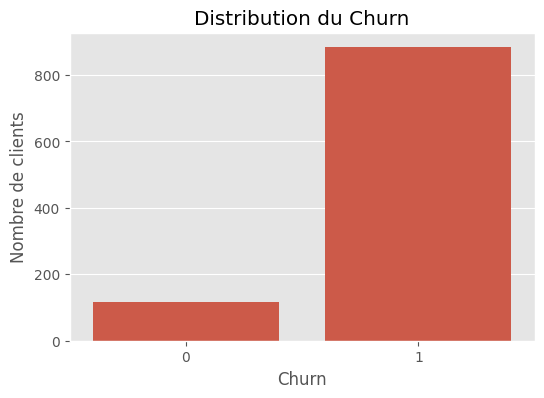

In [66]:
plt.style.use("ggplot")
plt.figure(figsize=(6,4))
sns.countplot(x="Churn", data=df)
plt.title("Distribution du Churn")
plt.xlabel("Churn")
plt.ylabel("Nombre de clients")
plt.show()

**Observation :**

Nous observons une majorité de clients ayant quitté l’entreprise, ce qui indique un fort taux de churn.
Cela peut avoir un impact important sur la performance des modèles.

# 2. Churn vs Tenure

***Relation entre la durée d'abonnement (Tenure) et le churn***

In [67]:
df.groupby("Churn")["Tenure"].mean()

Churn
0    30.264957
1    17.476784
Name: Tenure, dtype: float64

**Description:**

Nous analysons la durée moyenne d'abonnement des clients selon leur statut (churn ou non) afin d’identifier une éventuelle relation.

**Observation :**

Les clients ayant quitté l’entreprise ont généralement une durée d’abonnement plus courte.
Cela indique que les nouveaux clients sont plus susceptibles de quitter.

**Visualisation de la relation entre Tenure et Churn**

Ce graphique permet de comparer la distribution de la durée d'abonnement
entre les clients qui quittent l'entreprise et ceux qui restent.

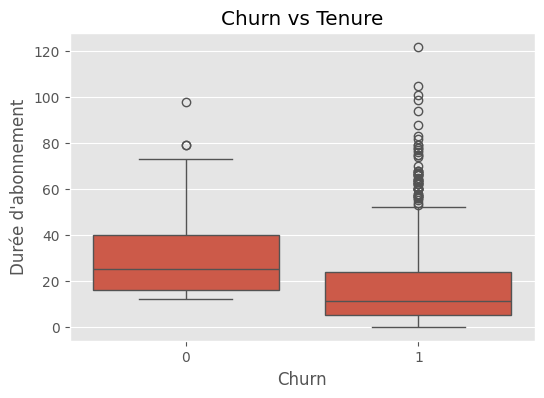

In [68]:
plt.style.use("ggplot")
plt.figure(figsize=(6,4))
sns.boxplot(x="Churn", y="Tenure", data=df)
plt.title("Churn vs Tenure")
plt.xlabel("Churn")
plt.ylabel("Durée d'abonnement")
plt.show()

# 3. Churn vs MonthlyCharges

***Relation entre les charges mensuelles et le churn***

In [69]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
0    62.54641
1    75.96077
Name: MonthlyCharges, dtype: float64

**Description:**

Nous comparons les charges mensuelles moyennes entre les clients qui quittent et ceux qui restent.

**Observation:**

Les clients ayant des charges mensuelles plus élevées ont tendance à quitter davantage, ce qui peut indiquer une sensibilité au prix.

**Visualisation des charges mensuelles selon le churn**

Ce graphique permet d'observer la distribution des charges mensuelles
pour les clients qui quittent l'entreprise et ceux qui restent.

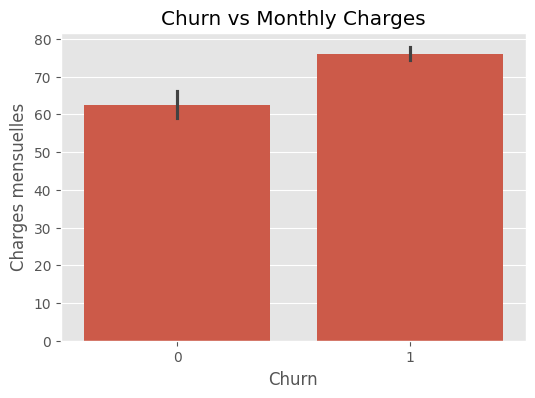

In [70]:
plt.style.use("ggplot")
plt.figure(figsize=(6,4))
sns.barplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Churn vs Monthly Charges")
plt.xlabel("Churn")
plt.ylabel("Charges mensuelles")
plt.show()

# 4. Churn vs ContractType

*Impact du type de contrat sur le churn*

In [71]:
df.groupby("Churn")[["ContractType_One-Year", "ContractType_Two-Year"]].mean()

,ContractType_One-Year,ContractType_Two-Year
Churn,,
0,0.606838,0.393162
1,0.246886,0.174405


**Description:**

Nous analysons l'influence du type de contrat sur la probabilité de churn.

**Observation:**

Les clients ayant des contrats à long terme (One-Year ou Two-Year) quittent moins que ceux avec des contrats mensuels.

**Visualisation de l'impact du type de contrat sur le churn**

Ce graphique illustre la proportion des différents types de contrats
selon le statut du client (churn ou non).

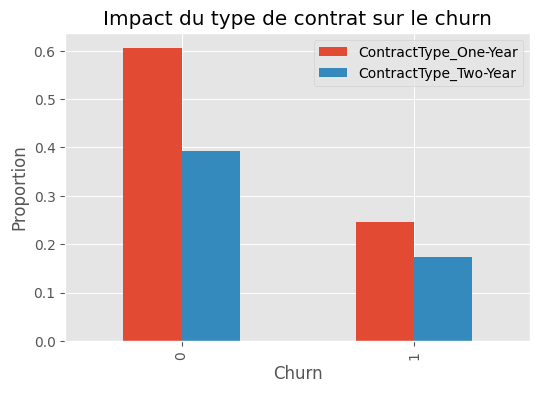

In [72]:
plt.style.use("ggplot")
contract_cols = ["ContractType_One-Year","ContractType_Two-Year"]

df_contract = df.groupby("Churn")[contract_cols].mean()

df_contract.plot(kind="bar", figsize=(6,4))
plt.title("Impact du type de contrat sur le churn")
plt.ylabel("Proportion")
plt.show()

# Correlation Matrix

La matrice de corrélation permet d'identifier les relations
entre les différentes variables du dataset.

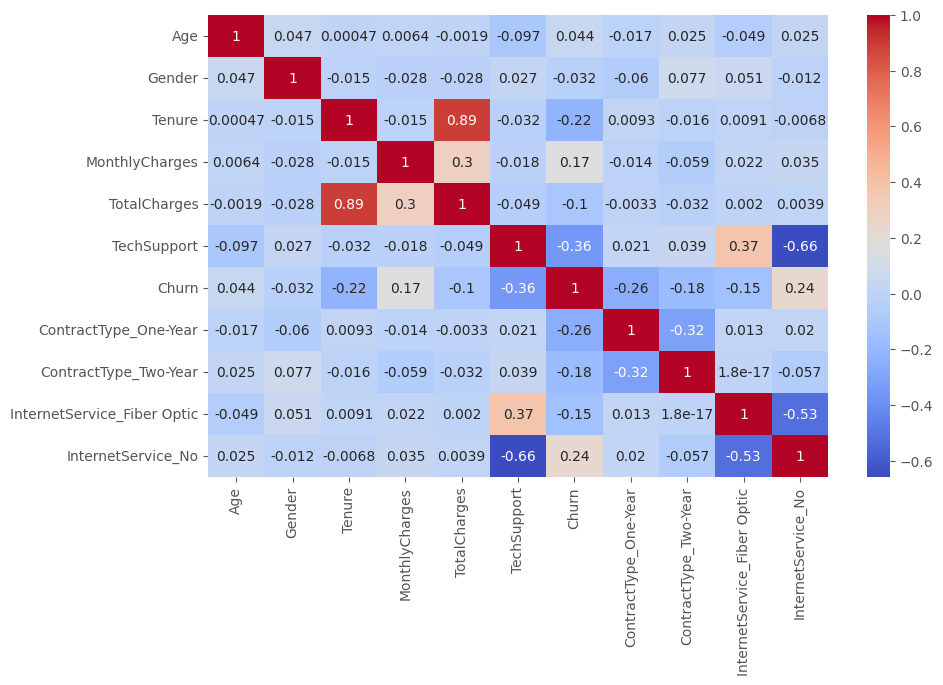

In [73]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.show()

**Observation :**

Certaines variables présentent une corrélation avec le churn, notamment Tenure et MonthlyCharges.
Cela indique qu'elles peuvent être importantes pour la prédiction.

# Conclusion de l'analyse exploratoire
L'analyse exploratoire des données a permis d'identifier
plusieurs facteurs susceptibles d'influencer le churn.

Les variables les plus importantes semblent être :

- la durée d'abonnement (Tenure)
- les charges mensuelles (MonthlyCharges)
- le type de contrat (ContractType)

Ces variables seront particulièrement utiles pour
la construction des modèles de Machine Learning.


## ****Feature Engineering****

Dans cette étape, nous créons de nouvelles variables afin d'améliorer la performance des modèles et d'extraire des informations plus pertinentes à partir des données existantes.

Ces variables permettent de mieux représenter le comportement des clients et d’identifier les facteurs influençant le churn.

# Feature 1: AvgCharge

In [74]:
df["AvgCharge"] = df["TotalCharges"] / (df["Tenure"] + 1)

### AvgCharge (charge moyenne mensuelle)

Cette variable représente la dépense moyenne mensuelle du client.

Pourquoi ?
Deux clients peuvent avoir le même montant total dépensé, mais sur des durées différentes.

Rôle :
Elle permet de mieux comprendre le comportement de paiement du client.

Impact :
Les clients ayant des charges mensuelles élevées peuvent être plus susceptibles de quitter le service.

# Feature 2: TenureGroup

In [75]:
df["TenureGroup"] = pd.cut(
    df["Tenure"],
    bins=[-1, 12, 24, 60, 1000],
    labels=[0, 1, 2, 3]
)

### TenureGroup (catégorisation de la durée d'abonnement)

Cette variable regroupe les clients selon leur ancienneté.

Pourquoi ?
Les nouveaux clients et les anciens n'ont pas le même comportement.

Rôle :
Elle simplifie l’analyse en regroupant les clients en catégories.

Impact :
Les nouveaux clients sont généralement plus susceptibles de quitter que les clients fidèles.

In [76]:
df["TenureGroup"] = df["TenureGroup"].astype(int)

# Sauvegarde du dataset

Après le preprocessing et le feature engineering, nous sauvegardons le dataset afin de permettre aux membres de l’équipe de travailler sur les mêmes données propres.

Cela garantit la cohérence des résultats et facilite la collaboration.

In [77]:
df.to_csv("cleaned_churn_data.csv", index=False)

In [78]:
df = pd.read_csv("cleaned_churn_data.csv")

In [79]:
df.head(5)

,Age,Gender,Tenure,MonthlyCharges,TotalCharges,TechSupport,Churn,ContractType_One-Year,ContractType_Two-Year,InternetService_Fiber Optic,InternetService_No,AvgCharge,TenureGroup
0,49,0,4,88.35,353.40,1,1,0,0,1,0,70.680000,0
1,43,0,0,36.67,0.00,1,1,0,0,1,0,0.000000,0
2,51,1,2,63.79,127.58,0,1,0,0,1,0,42.526667,0
3,60,1,8,102.34,818.72,1,1,1,0,0,0,90.968889,0
4,42,0,32,69.01,2208.32,0,1,0,0,0,1,66.918788,2


## Préparation des données pour la modélisation

Dans cette étape, nous préparons les données avant l'entraînement des modèles de Machine Learning.

Nous commençons par séparer :

* les variables explicatives (X)
* la variable cible (y)

La variable cible est Churn, qui indique si le client quitte (1) ou reste (0).

# Séparation des variables

In [80]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

## Division des données en ensemble d'entraînement et de test

Nous divisons le dataset en deux parties :

* Ensemble d'entraînement (80%) : utilisé pour entraîner le modèle
* Ensemble de test (20%) : utilisé pour évaluer les performances

Nous utilisons également l'option stratify pour conserver la même distribution de la variable cible dans les deux ensembles, car le dataset est déséquilibré.

In [81]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardisation des données

La standardisation permet de mettre toutes les variables sur la même échelle.

Cela est important pour certains modèles de Machine Learning (comme KNN ou Logistic Regression), car ils sont sensibles à l’échelle des données.

Nous utilisons StandardScaler pour transformer les données :

* fit_transform est appliqué sur les données d'entraînement
* transform est appliqué sur les données de test

Cela permet d'éviter le data leakage.

In [82]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipeline_preprocessing = Pipeline([
    ("scaler", StandardScaler())
])

X_train = pipeline_preprocessing.fit_transform(X_train)
X_test = pipeline_preprocessing.transform(X_test)

## Vérification finale

Nous vérifions la taille des ensembles d'entraînement et de test.

In [83]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (800, 12)
X_test: (200, 12)


## Conclusion

Les données sont maintenant :

* nettoyées
* transformées
* standardisées
* prêtes pour l'entraînement des modèles

Les variables les plus importantes identifiées sont :

* Tenure
* MonthlyCharges
* ContractType
* AvgCharge

La prochaine étape consiste à entraîner et comparer plusieurs modèles de classification.